# Лабораторная работа №1: регрессия

**Данные:** [Wine Quality (UCI)](https://archive.ics.uci.edu/dataset/186/wine+quality) — физико-химические показатели красных и белых вин *vinho verde* и экспертная оценка `quality`.

**Задача:** предсказать `quality`. **Метрики:** RMSE (порог < 0.70) и MAE.

In [1]:
import io
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

## 1. Загрузка данных

Объединяю красные и белые вина в одну таблицу и добавляю признак `is_red`. Если файлов нет в `data/`, они скачиваются с сайта UCI.

In [2]:
DATA_DIR = Path("data")
files = [DATA_DIR / "winequality-red.csv", DATA_DIR / "winequality-white.csv"]
if not all(f.exists() for f in files):
    url = "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"
    with urllib.request.urlopen(url, timeout=60) as response:
        zipfile.ZipFile(io.BytesIO(response.read())).extractall(DATA_DIR)

red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";")
red["is_red"] = 1
white["is_red"] = 0

df = pd.concat([red, white], ignore_index=True)
df.columns = df.columns.str.replace(" ", "_")
print("Размер:", df.shape)
df.head()

Размер: (6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [3]:
df.info()
print()
print("Пропусков:", df.isna().sum().sum())
print("Полных дубликатов строк:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB

Пропусков: 0
Полных дубликатов строк: 1177


**Выводы.** Пропусков нет, все признаки числовые. 1177 строк (18%) — полные дубликаты. Удаляю их до разбиения, иначе копии попадут и в train, и в test (утечка).

In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print("После удаления дубликатов:", df.shape)

После удаления дубликатов: (5320, 13)


## 2. Разбиение на train и test

In [5]:
X = df.drop(columns="quality")
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("train:", X_train.shape, " test:", X_test.shape)

pd.DataFrame({
    "доля в train": y_train.value_counts(normalize=True),
    "доля в test": y_test.value_counts(normalize=True),
}).sort_index().round(3)

train: (4256, 12)  test: (1064, 12)


,доля в train,доля в test
quality,,
3,0.006,0.006
4,0.039,0.039
5,0.329,0.329
6,0.437,0.437
7,0.161,0.161
8,0.028,0.028
9,0.001,0.001


- **Размер:** 80/20 (4256 и 1064 вина) — достаточно данных и для обучения, и для устойчивой оценки.
- **Способ:** случайное разбиение со стратификацией по `quality`: оценки несбалансированы (девяток всего 5), а так их доли в train и test совпадают. `random_state=42` — для воспроизводимости.
- **Почему нельзя много раз оценивать на одном тесте:** решение подгоняется под конкретный тест, и оценка становится завышенной. Поэтому тест используется только для финальной оценки, а единственный подбираемый параметр (`max_features` у леса) выбран по кросс-валидации на train.

## 3. Исследовательский анализ (только train)

In [6]:
train = X_train.copy()
train["quality"] = y_train
train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed_acidity,4256.0,7.225,1.332,4.200,6.400,7.000,7.700,15.900
volatile_acidity,4256.0,0.343,0.167,0.080,0.230,0.300,0.410,1.580
citric_acid,4256.0,0.319,0.147,0.000,0.250,0.310,0.390,1.660
residual_sugar,4256.0,5.002,4.450,0.600,1.800,2.700,7.400,65.800
chlorides,4256.0,0.057,0.036,0.009,0.038,0.047,0.066,0.611
free_sulfur_dioxide,4256.0,29.992,17.824,1.000,17.000,28.000,40.125,289.000
total_sulfur_dioxide,4256.0,113.737,56.554,7.000,74.000,115.750,153.000,440.000
density,4256.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,4256.0,3.224,0.160,2.720,3.110,3.210,3.330,4.010
sulphates,4256.0,0.533,0.146,0.220,0.430,0.510,0.600,1.980


**Выводы.** Признаки в очень разных масштабах — для сравнения весов линейной регрессии нужна стандартизация. У `residual_sugar`, `chlorides`, `free_sulfur_dioxide` есть выбросы.

### 3.1. Целевая переменная

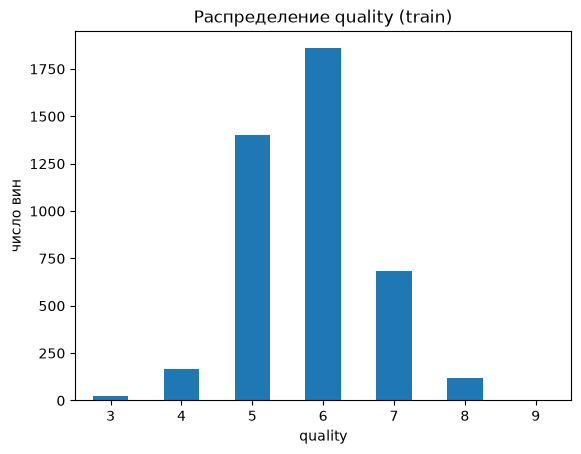

Среднее quality: 5.795  std: 0.88
Доля оценок 5, 6, 7: 0.927
Среднее quality: белые 5.853  красные 5.628


In [7]:
y_train.value_counts().sort_index().plot.bar(rot=0)
plt.title("Распределение quality (train)")
plt.xlabel("quality")
plt.ylabel("число вин")
plt.show()

print("Среднее quality:", round(y_train.mean(), 3), " std:", round(y_train.std(), 3))
print("Доля оценок 5, 6, 7:", round(y_train.isin([5, 6, 7]).mean(), 3))
print("Среднее quality: белые", round(train.loc[train.is_red == 0, "quality"].mean(), 3),
      " красные", round(train.loc[train.is_red == 1, "quality"].mean(), 3))

**Выводы.** 93% оценок — 5, 6 или 7, крайних оценок мало, поэтому их модель будет предсказывать хуже. Std ≈ 0.88 — примерно такой RMSE даёт прогноз константой, значит, ошибку нужно снизить примерно на 20%.

### 3.2. Связь признаков с качеством

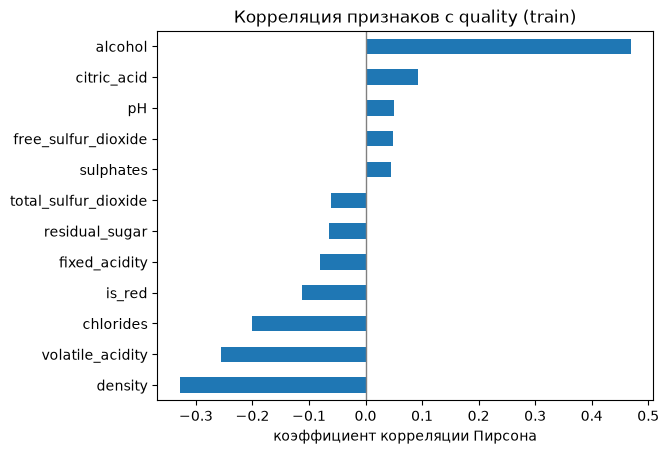

alcohol                 0.469
density                -0.328
volatile_acidity       -0.256
chlorides              -0.201
is_red                 -0.112
citric_acid             0.094
fixed_acidity          -0.080
residual_sugar         -0.065
total_sulfur_dioxide   -0.061
pH                      0.051
free_sulfur_dioxide     0.049
sulphates               0.045
Name: quality, dtype: float64

In [8]:
corr_with_quality = train.corr()["quality"].drop("quality")

corr_with_quality.sort_values().plot.barh()
plt.axvline(0, color="gray", linewidth=1)
plt.title("Корреляция признаков с quality (train)")
plt.xlabel("коэффициент корреляции Пирсона")
plt.show()

corr_with_quality.sort_values(key=abs, ascending=False).round(3)

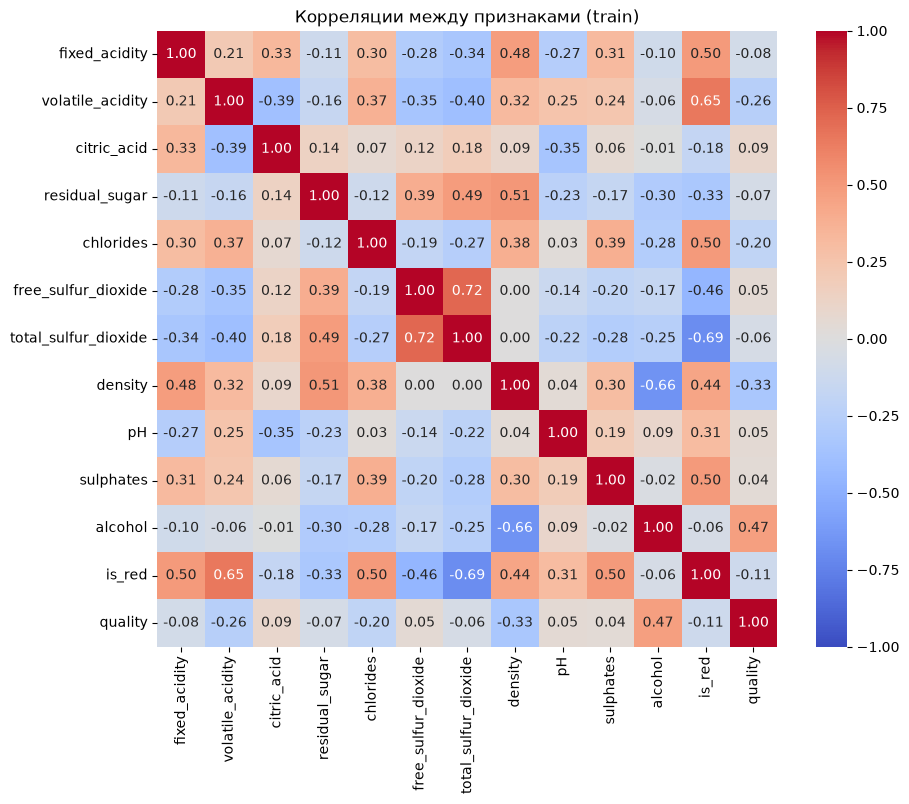

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(train.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляции между признаками (train)")
plt.show()

**Выводы.**
- Сильнее всего с качеством связан `alcohol` (0.47). Отрицательно — `density` (−0.33, в основном через спирт), `volatile_acidity` (−0.26) и `chlorides` (−0.20).
- Остальные признаки связаны слабо, но корреляция видит только линейную связь.
- Признаки связаны между собой (`density` и `alcohol` −0.66, свободный и общий SO₂ 0.72), поэтому веса линейной регрессии нужно читать осторожно.

### 3.3. Свободный SO₂ по типам вина

In [10]:
so2_bins = pd.cut(train["free_sulfur_dioxide"], [0, 5, 10, 20, 30, 40, 60, 80, 300])
wine_type = train["is_red"].map({0: "белые", 1: "красные"})
so2_table = train.groupby([so2_bins, wine_type], observed=True)["quality"].agg(["mean", "count"]).unstack()
so2_table.round(2)

mean          count        
is_red              белые красные  белые красные
free_sulfur_dioxide                             
(0, 5]               4.72    5.56   36.0   131.0
(5, 10]              5.25    5.72  113.0   278.0
(10, 20]             5.77    5.64  486.0   372.0
(20, 30]             5.96    5.57  765.0   195.0
(30, 40]             6.02    5.56  728.0    88.0
(40, 60]             5.83    5.54  811.0    26.0
(60, 80]             5.71    5.00  195.0     2.0
(80, 300]            5.53     NaN   30.0     NaN

**Вывод.** У белых вин зависимость в форме «горки» (4.72 → 6.02 → 5.53), у красных её нет. Корреляция такую связь не видит (0.05), а деревья смогут её использовать.

**Итоги EDA:** главные признаки — `alcohol` и `volatile_acidity`; есть нелинейность и различия между типами вин, поэтому деревья, скорее всего, обгонят линейную регрессию; крайние оценки будут предсказываться хуже.

## 4. Метрики и baseline

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat y_i|, \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2}$$

- **MAE** — на сколько баллов модель ошибается в среднем.
- **RMSE** — тоже ошибка в баллах, но сильнее реагирует на большие ошибки, потому что они возводятся в квадрат: ошибка в 4 раза больше даёт вклад в 16 раз больше.
- Всегда RMSE ≥ MAE. Чем неравномернее ошибки (редкие крупные промахи), тем сильнее они различаются.

**Baseline** — прогноз одной константой. Для RMSE лучшая константа — среднее, для MAE — медиана. Проверка на train:

In [11]:
for name, const in [("среднее", y_train.mean()), ("медиана", y_train.median())]:
    pred = np.full(len(y_train), const)
    print(f"{name} = {const:.3f}:  RMSE {root_mean_squared_error(y_train, pred):.3f},"
          f"  MAE {mean_absolute_error(y_train, pred):.3f}  (на train)")

среднее = 5.795:  RMSE 0.880,  MAE 0.695  (на train)
медиана = 6.000:  RMSE 0.903,  MAE 0.643  (на train)


Беру среднее. Функция `evaluate` обучает модель на train и считает RMSE и MAE на test, а также RMSE на train для сравнения.

In [12]:
results = {}


def evaluate(name, model):
    """Обучает модель на train и считает метрики на test (и RMSE на train для сравнения)."""
    model.fit(X_train, y_train)
    pred_test = model.predict(X_test)
    results[name] = {
        "RMSE": root_mean_squared_error(y_test, pred_test),
        "MAE": mean_absolute_error(y_test, pred_test),
        "train RMSE": root_mean_squared_error(y_train, model.predict(X_train)),
    }
    return pd.Series(results[name]).round(3)


baseline = DummyRegressor(strategy="mean")
evaluate("Baseline", baseline)

RMSE          0.880
MAE           0.695
train RMSE    0.880
dtype: float64

Baseline: RMSE 0.880, MAE 0.695 — точка отсчёта.

## 5. Модели

### 5.1. Линейная регрессия

Признаки стандартизуются внутри `Pipeline`, поэтому среднее и std считаются только по train.

In [13]:
lin_reg = make_pipeline(StandardScaler(), LinearRegression())
evaluate("Linear Regression", lin_reg)

RMSE          0.729
MAE           0.566
train RMSE    0.731
dtype: float64

In [14]:
lin_raw = LinearRegression().fit(X_train, y_train)
print("Предсказания с масштабированием и без совпадают:",
      np.allclose(lin_raw.predict(X_train), lin_reg.predict(X_train)))

coefs = pd.DataFrame({
    "без масштабирования": lin_raw.coef_,
    "после StandardScaler": lin_reg[-1].coef_,
}, index=X_train.columns).sort_values("после StandardScaler", key=abs, ascending=False)
coefs.round(3)

Предсказания с масштабированием и без совпадают: True


,без масштабирования,после StandardScaler
density,-94.718,-0.281
alcohol,0.231,0.276
residual_sugar,0.051,0.227
volatile_acidity,-1.326,-0.221
sulphates,0.804,0.117
is_red,0.260,0.114
free_sulfur_dioxide,0.006,0.112
pH,0.666,0.107
total_sulfur_dioxide,-0.002,-0.105
fixed_acidity,0.073,0.097


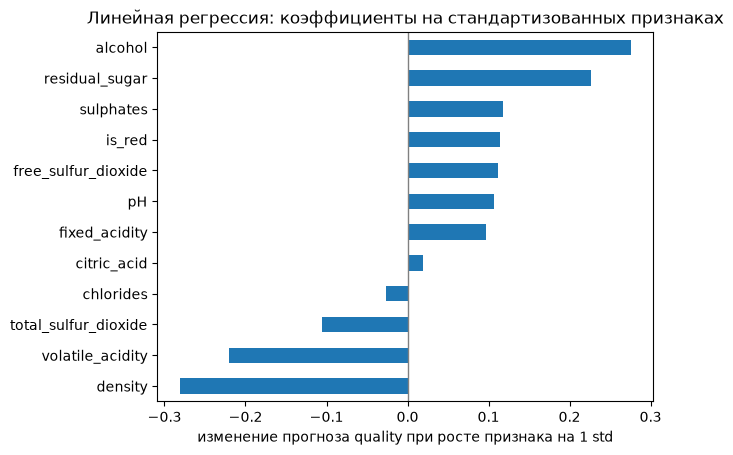

In [15]:
coefs["после StandardScaler"].sort_values().plot.barh()
plt.axvline(0, color="gray", linewidth=1)
plt.title("Линейная регрессия: коэффициенты на стандартизованных признаках")
plt.xlabel("изменение прогноза quality при росте признака на 1 std")
plt.show()

**Анализ.**
- RMSE 0.729 — лучше baseline, но порог не пройден. RMSE на train почти такой же, значит, модель недообучена.
- Масштабирование не меняет прогнозы (`True`), но нужно, чтобы сравнивать веса: сырые веса зависят от единиц измерения (у `density` −94.7).
- По стандартизованным весам важнее всего `density`, `alcohol`, `residual_sugar`, `volatile_acidity`. Надёжны знаки `alcohol` (+) и `volatile_acidity` (−); большие веса `density` и `residual_sugar` — следствие мультиколлинеарности.

### 5.2. Random Forest

Много глубоких деревьев на случайных подвыборках, прогноз — их среднее. `max_features` выбираю по 5-fold кросс-валидации на train.

In [16]:
for max_features in [1.0, "sqrt"]:
    candidate = RandomForestRegressor(n_estimators=300, max_features=max_features,
                                      random_state=RANDOM_STATE, n_jobs=-1)
    scores = -cross_val_score(candidate, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    print(f"max_features={max_features!r}:  CV RMSE {scores.mean():.3f}  (разброс между частями {scores.std():.3f})")

max_features=1.0:  CV RMSE 0.693  (разброс между частями 0.012)


max_features='sqrt':  CV RMSE 0.686  (разброс между частями 0.009)


`"sqrt"` немного лучше (0.686 против 0.693), беру его.

In [17]:
rf = RandomForestRegressor(n_estimators=300, max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1)
evaluate("Random Forest", rf)

RMSE          0.680
MAE           0.526
train RMSE    0.252
dtype: float64

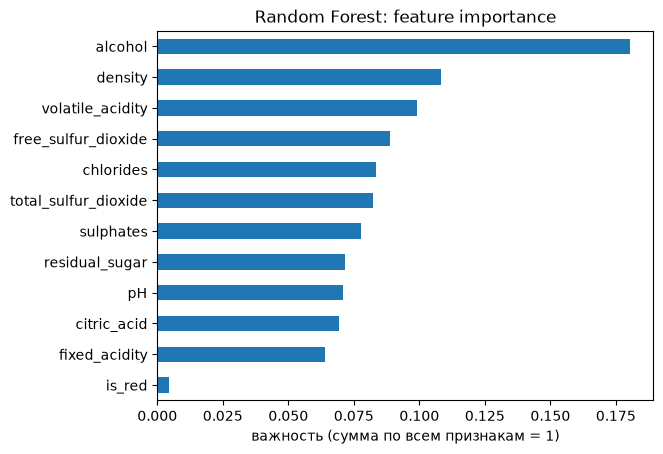

In [18]:
rf_importance = pd.Series(rf.feature_importances_, index=X_train.columns)

rf_importance.sort_values().plot.barh()
plt.title("Random Forest: feature importance")
plt.xlabel("важность (сумма по всем признакам = 1)")
plt.show()

**Анализ.**
- RMSE 0.680, MAE 0.526 — лучшая модель, порог пройден. Низкий RMSE на train (0.25) для леса нормален: деревья почти запоминают обучающие данные.
- Главные признаки: `alcohol`, `density`, `volatile_acidity` — как в EDA и в линейной регрессии. `free_sulfur_dioxide` на 4-м месте, хотя корреляция почти нулевая: лес использует «горку».

### 5.3. Gradient Boosting

Деревья строятся по очереди, каждое исправляет ошибки предыдущих. Параметры по умолчанию.

In [19]:
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)
evaluate("Gradient Boosting", gb)

RMSE          0.694
MAE           0.539
train RMSE    0.640
dtype: float64

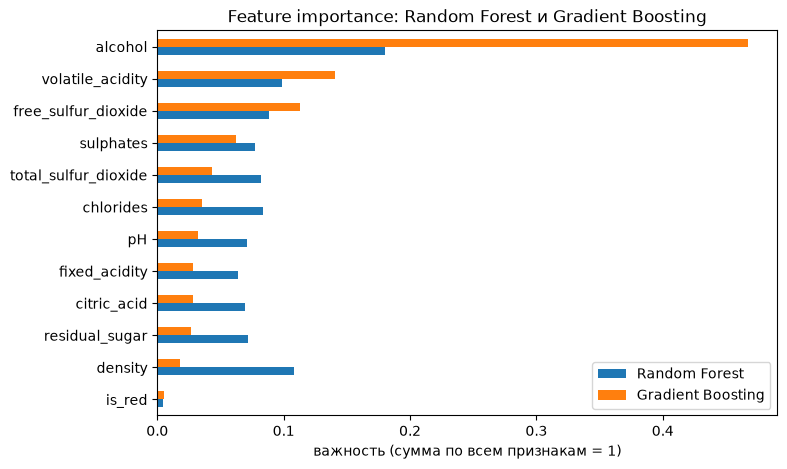

,Random Forest,Gradient Boosting
alcohol,0.180,0.467
volatile_acidity,0.099,0.141
free_sulfur_dioxide,0.089,0.113
sulphates,0.078,0.062
total_sulfur_dioxide,0.082,0.044
chlorides,0.083,0.035
pH,0.071,0.032
fixed_acidity,0.064,0.028
citric_acid,0.069,0.028
residual_sugar,0.071,0.027


In [20]:
importance = pd.DataFrame({
    "Random Forest": rf_importance,
    "Gradient Boosting": pd.Series(gb.feature_importances_, index=X_train.columns),
}).sort_values("Gradient Boosting")

importance.plot.barh(figsize=(8, 5))
plt.title("Feature importance: Random Forest и Gradient Boosting")
plt.xlabel("важность (сумма по всем признакам = 1)")
plt.show()

importance.sort_values("Gradient Boosting", ascending=False).round(3)

**Анализ.**
- RMSE 0.694, MAE 0.539 — порог пройден, но хуже леса. Модель слегка недообучена (RMSE на train 0.64).
- Лидеры те же (`alcohol`, `volatile_acidity`, `free_sulfur_dioxide`), но бустинг сильнее опирается на `alcohol` (0.47 против 0.18 у леса), а `density` почти не использует: она дублирует спирт.

## 6. Итоговая таблица

In [21]:
summary = pd.DataFrame(results).T
summary["лучше baseline"] = summary["RMSE"] < summary.loc["Baseline", "RMSE"]
summary["RMSE < 0.70"] = summary["RMSE"] < 0.70
summary.round(3)

,RMSE,MAE,train RMSE,лучше baseline,RMSE < 0.70
Baseline,0.880,0.695,0.880,False,False
Linear Regression,0.729,0.566,0.731,True,False
Random Forest,0.680,0.526,0.252,True,True
Gradient Boosting,0.694,0.539,0.640,True,True


Все три модели лучше baseline, порог 0.70 проходят Random Forest и Gradient Boosting.
- **Деревья лучше линейной регрессии:** зависимость нелинейная и разная у типов вин, а линейная регрессия недообучена.
- **Лес немного лучше бустинга:** данные шумные (оценки дегустаторов), а усреднение многих деревьев хорошо справляется с шумом.
- Обе ансамблевые модели упираются примерно в 0.68: часть ошибки — неустранимый шум оценок.

## 7. Feature importance: сравнение моделей и EDA

In [22]:
ranks = pd.DataFrame({
    "|корреляция| (EDA)": corr_with_quality.abs(),
    "|коэф.| LR": coefs["после StandardScaler"].abs(),
    "Random Forest": importance["Random Forest"],
    "Gradient Boosting": importance["Gradient Boosting"],
}).rank(ascending=False).astype(int).sort_values("Random Forest")
ranks

,|корреляция| (EDA),|коэф.| LR,Random Forest,Gradient Boosting
alcohol,1,2,1,1
density,2,1,2,11
volatile_acidity,3,4,3,2
free_sulfur_dioxide,11,7,4,3
chlorides,4,11,5,6
total_sulfur_dioxide,9,9,6,5
sulphates,12,5,7,4
residual_sugar,8,3,8,10
pH,10,8,9,7
citric_acid,6,12,10,9


**Выводы.** `alcohol` и `volatile_acidity` важны во всех методах. `free_sulfur_dioxide` недооценён корреляцией, но важен для деревьев. `density` у разных моделей на разных местах, потому что дублирует спирт.

**Можно ли считать важный признак причиной изменения качества?** Нет. Важность показывает, насколько признак помогает прогнозу, а не причинную связь: данные наблюдательные, связанные признаки подменяют друг друга, а важность зависит от модели. Для причинности нужен эксперимент.

## 8. Анализ ошибок лучшей модели (Random Forest)

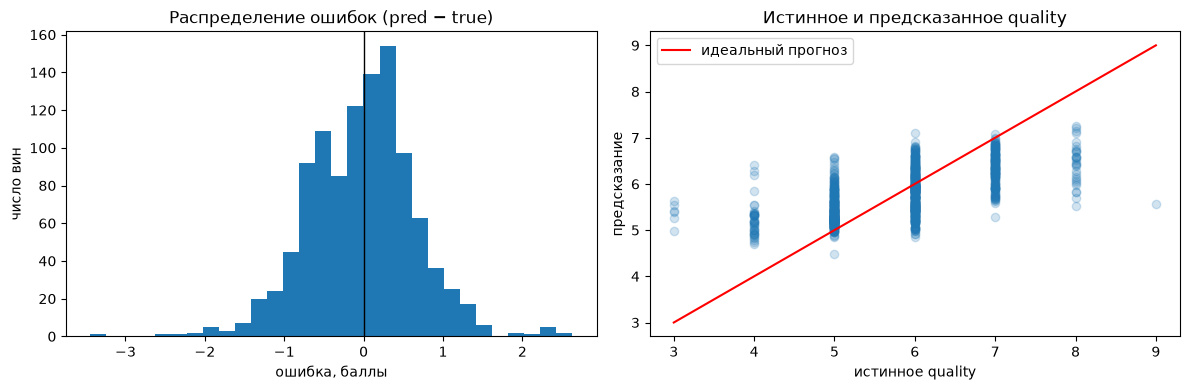

Средняя ошибка: -0.022
Доля ошибок меньше 0.5 балла: 0.562
Доля ошибок от 1 балла и больше: 0.12
Диапазон предсказаний: 4.49 – 7.25


In [23]:
errors = X_test.copy()
errors["true"] = y_test
errors["pred"] = rf.predict(X_test)
errors["error"] = errors["pred"] - errors["true"]  # > 0 — модель завысила оценку
errors["abs_error"] = errors["error"].abs()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(errors["error"], bins=30)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set(title="Распределение ошибок (pred − true)", xlabel="ошибка, баллы", ylabel="число вин")
axes[1].scatter(errors["true"], errors["pred"], alpha=0.2)
axes[1].plot([3, 9], [3, 9], color="red", label="идеальный прогноз")
axes[1].set(title="Истинное и предсказанное quality", xlabel="истинное quality", ylabel="предсказание")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Средняя ошибка:", round(errors["error"].mean(), 3))
print("Доля ошибок меньше 0.5 балла:", round((errors["abs_error"] < 0.5).mean(), 3))
print("Доля ошибок от 1 балла и больше:", round((errors["abs_error"] >= 1).mean(), 3))
print("Диапазон предсказаний:", round(errors["pred"].min(), 2), "–", round(errors["pred"].max(), 2))

Ошибки симметричны вокруг нуля, но прогнозы сжаты к среднему: все они лежат в диапазоне 4.49–7.25, а настоящие оценки — от 3 до 9.

In [24]:
errors.groupby("true").agg(
    count=("error", "size"),
    mean_pred=("pred", "mean"),
    mean_error=("error", "mean"),
    MAE=("abs_error", "mean"),
).round(3)

,count,mean_pred,mean_error,MAE
true,,,,
3,6,5.368,2.368,2.368
4,41,5.230,1.230,1.230
5,350,5.426,0.426,0.433
6,465,5.841,-0.159,0.386
7,171,6.335,-0.665,0.666
8,30,6.450,-1.550,1.550
9,1,5.557,-3.443,3.443


Оценки 5–6 предсказываются хорошо (MAE около 0.4), плохие вина модель завышает, хорошие — занижает.

In [25]:
cols = ["is_red", "true", "pred", "error", "alcohol", "volatile_acidity", "free_sulfur_dioxide", "sulphates"]
errors.sort_values("abs_error", ascending=False).head(10)[cols].round(2)

,is_red,true,pred,error,alcohol,volatile_acidity,free_sulfur_dioxide,sulphates
2012,0,9,5.56,-3.44,10.4,0.27,28.0,0.46
1982,0,3,5.63,2.63,12.6,0.39,5.0,0.37
1571,0,3,5.53,2.53,9.8,0.26,41.0,0.50
2549,0,8,5.52,-2.48,10.5,0.22,12.0,0.38
2783,0,3,5.42,2.42,9.4,0.25,118.5,0.63
4984,0,4,6.41,2.41,11.5,0.26,75.0,0.38
1165,1,3,5.38,2.38,9.8,0.82,16.0,0.51
3881,0,8,5.70,-2.30,12.5,0.53,6.0,0.50
4158,0,4,6.29,2.29,12.9,0.64,18.0,0.60
1245,1,3,5.27,2.27,9.7,0.98,20.0,0.55


Медианы признаков в train для каждой оценки — для сравнения:

In [26]:
train.groupby("quality")[["alcohol", "volatile_acidity", "free_sulfur_dioxide", "sulphates"]].median()

,alcohol,volatile_acidity,free_sulfur_dioxide,sulphates
quality,,,,
3,10.45,0.46,17.0,0.505
4,10.10,0.38,15.0,0.490
5,9.60,0.34,26.0,0.510
6,10.50,0.27,29.0,0.510
7,11.50,0.28,29.0,0.520
8,12.20,0.29,31.5,0.500
9,12.60,0.31,29.0,0.450


**Крупные ошибки** — все на редких оценках 3, 4, 8, 9:
- **#2012** (оценка 9, прогноз 5.56): по химии обычное вино, спирт 10.4 — как у оценки 6.
- **#1982** (оценка 3, прогноз 5.63): высокий спирт (12.6), но мало SO₂ (5 мг/л) — противоречивые сигналы.
- **#1165** (оценка 3, прогноз 5.38): высокая летучая кислотность (0.82), модель видит, что вино плохое, но всё равно тянет прогноз к среднему.

**Почему редкие оценки хуже:** мало примеров, квадратичная ошибка тянет прогноз к среднему, деревья усредняют оценки в листьях, а сами оценки шумные.

## 9. Итоговые выводы

- Удалены 1177 дубликатов; разбиение 80/20 со стратификацией; EDA и выбор параметров — только по train.
- RMSE / MAE на тесте: baseline 0.880 / 0.695, линейная регрессия 0.729 / 0.566, **Random Forest 0.680 / 0.526**, Gradient Boosting 0.694 / 0.539.
- Лучшая модель — Random Forest; главные признаки — `alcohol` и `volatile_acidity`.
- Хуже всего модель предсказывает редкие крайние оценки.